In [26]:
import numpy as np
import re
import math
import sys
from collections import defaultdict
import json
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [94]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])
    
def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = 'p?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            data_dict[mesh_id].append(data)
    return data_dict

data = load_multichannel_data()

In [95]:
{key: value[0]['info']['mesh_layout'] for key, value in data.items()}

{'M-SP-PITCH-V2-0100-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0097-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0096-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0099-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0098-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0095-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0094-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0093-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0092-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0091-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0090-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0089-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0088-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0087-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0086-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0085-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0084-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0083-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0082-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0081-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0080-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0079-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0078-0.3': 'SP-PITCH-V2',
 'M-SP-PITCH-V2-0077-0.3': 'SP-PIT

In [50]:
len([val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:])
len(list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values()))

4

In [51]:
data['M-SP-PITCH-V2-0005-0.4'][-1]['data'].keys()

dict_keys(['cal', 'open_fwd', 'open_flip', 'load_fwd', 'load_flip', 'short_fwd', 'short_flip'])

Baseline threshold set at 0.999756
Within class: 1±0.000152 max: 1
Cross class: 1±5.71e-05 max: 1
Baseline false negative probability: 0.316954421705
Baseline false positive probability: 0.102950860625


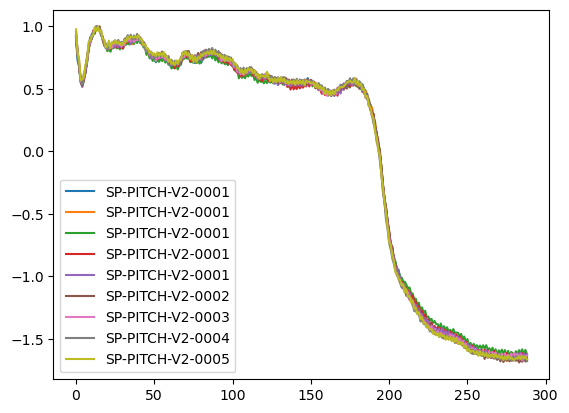

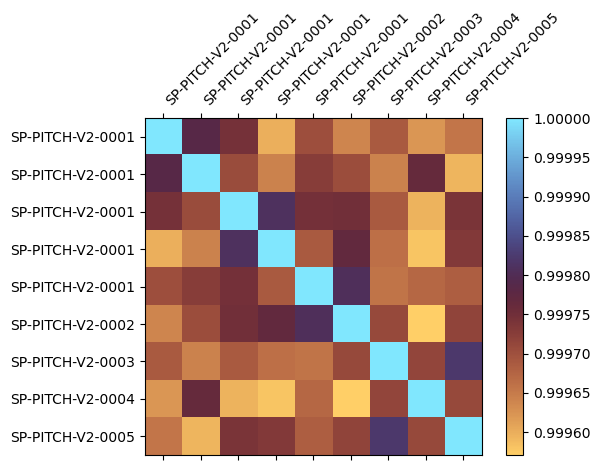

In [148]:
roi_map = {
    'tdp0604': (155, 445),
    'pi3hdx12211': (160, 450),
}
foo = list(roi_map.values())[0]
roi_n = foo[1] - foo[0]

def plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None):
    group_a, group_b = list(group_a), list(group_b)
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), roi_n))
    labels = []
    for i, trace in enumerate(all_traces):
        trace_data = trace['data'][select_trace][select_channel]
        start, end = roi_map[trace['info']['chip']]
        trace_data = trace_data[start:end]

        if smooth is not None:
            t = np.linspace(0, 1, len(trace_data))
            spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
            trace_data = spl(t)
        
        d[i] = trace_data
        labels.append(trace['info']['specimen'])
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,1:]
    deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    deltas /= np.repeat(deltas.max(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]
    
    corr = np.corrcoef(deltas)
    
    fig, ax = plt.subplots()
    for x, lab in zip(deltas, labels):
        ax.plot(x, label=lab)
    ax.legend()
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())
plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None)

Baseline threshold set at 0.977515
Within class: 0.985±0.0125 max: 1
Cross class: 0.97±0.00333 max: 0.976
Baseline false negative probability: 0.275084608731
Baseline false positive probability: 0.012601368191


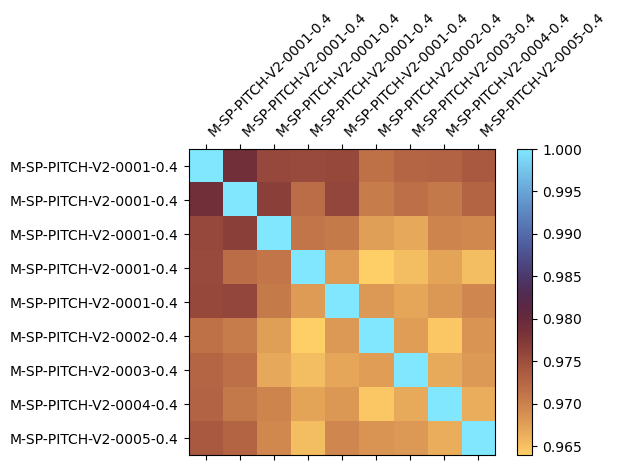

In [129]:
def plot_vector_covar(group_a, group_b, do_cal=False):
    group_a, group_b = list(group_a), list(group_b)
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), 12, roi_n))
    labels = []
    for i, entry in enumerate(all_traces):
        start, end = roi_map[entry['info']['chip']]
        labels.append(entry['info']['mesh_id'])
        for j, (term, direction, channel) in enumerate(itertools.product(['open', 'short', 'load'], ['fwd', 'flip'], ['adc1', 'adc2'])):
            trace_data = np.array(entry['data'][f'{term}_{direction}'][channel])
            if do_cal:
                trace_data -= np.array(entry['data']['cal'][channel])
            d[i, j] = trace_data[start:end]
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,:,1:]
    deltas -= np.repeat(deltas.mean(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    deltas /= np.repeat(deltas.max(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]

    corr = np.zeros((12, len(all_traces), len(all_traces)))
    for i in range(12):
        corr[i] = np.corrcoef(deltas[:,i,:])
    corr = np.sqrt(np.mean(np.square(corr), axis=0))
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    #threshold = np.mean(within_class) -2*np.std(within_class)
    #threshold = (np.mean(within_class) + np.max(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b)

Baseline threshold set at 0.977515
Within class: 0.985±0.0125 max: 1
Cross class: 0.97±0.00333 max: 0.976
Baseline false negative probability: 0.275084608731
Baseline false positive probability: 0.012601368191


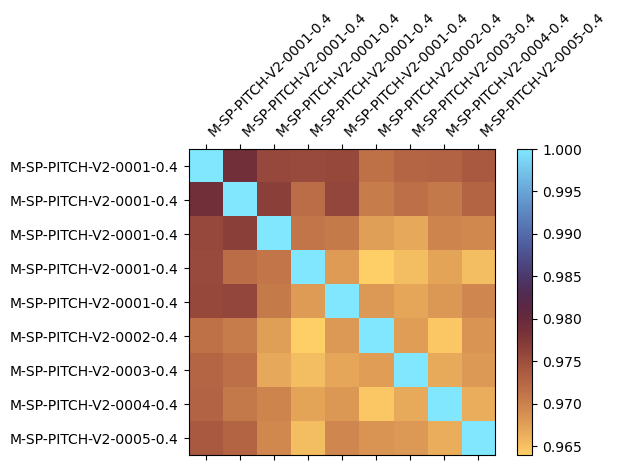

In [135]:
group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[2345]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b)

Baseline threshold set at 0.953971
Within class: 0.98±0.0162 max: 1
Cross class: 0.928±0.041 max: 0.969
Baseline false negative probability: 0.052809542587
Baseline false positive probability: 0.261067129910


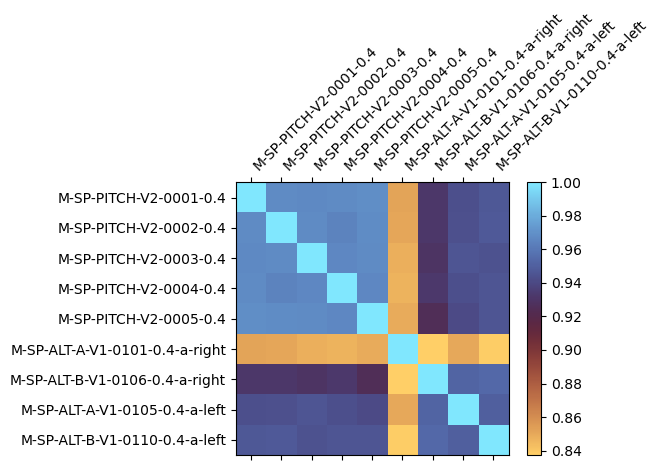

In [127]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b)

Baseline threshold set at 0.990668
Within class: 0.998±0.00154 max: 1
Cross class: 0.983±0.0229 max: 0.997
Baseline false negative probability: 0.000000553662
Baseline false positive probability: 0.371486182687


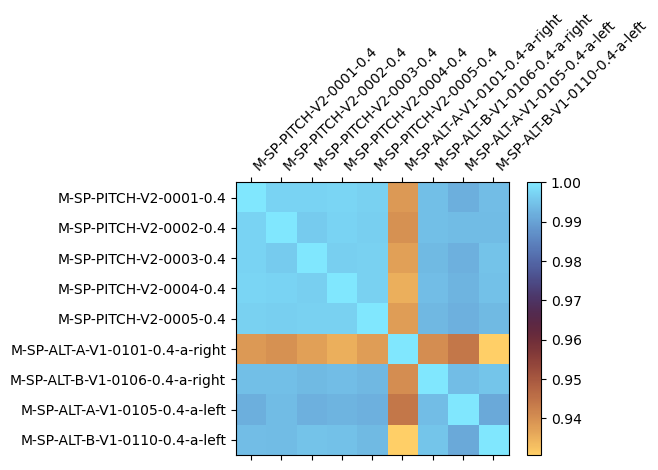

In [150]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, do_cal=False)